# A4: summary of all station-correction models

Every model of track A on the same test: 99 northern Frost stations in 5 spatially held-out groups
(each group is predicted by models trained on the other 4), test period 2025-04-01 – 2025-09-12,
runs present in both the ECMWF and the NWP samples.

* **Metric:** vector RMSE of the 10 m wind $(u, v)$, as a change in % against the mean of IFS and AIFS
  at the station. Negative = better.
* **Models:** an optional neural operator on the 0.25° fields + an MLP head on the 1 km terrain
  descriptors (see `00_project_overview.ipynb`). Learning rate $10^{-5}$, 3 seeds; the table shows
  the mean over seeds and its standard deviation.
* **Input groups** (the *inputs* column of the tables):

| label | models | provider | kind | native grid |
|---|---|---|---|---|
| **ECMWF** | IFS | ECMWF, open data | physical (NWP), global | 0.25° |
| | AIFS | ECMWF, open data | machine learning, global | 0.25° |
| **NWP** | IFS | ECMWF, open data | physical, global | 0.25° |
| | GFS | NOAA | physical, global | 0.25° |
| | MEPS | MET Norway (deterministic member) | physical, regional | 2.5 km |
| | AROME-Arctic | MET Norway | physical, regional | 2.5 km |

  The labels are short names: IFS is in both groups, and AIFS is a machine-learning model, not NWP.
  The reference and the *uncorrected* rows are the plain means of the group's models at the station.
  Observations: hourly 10 m wind from the MET Norway Frost API.


In [1]:
import json, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
sys.path.insert(0, '..')
from windcast.station_correction import station_groups
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
ROOT = Path('/cluster/work/projects/nn8106k/siyan/windcast'); RUNS = ROOT / 'runs_a1'
TAG = ROOT / 'cache/multimodel_2024-03-01_2025-09-12'
e, n = (dict(np.load(f'{TAG}{s}.npz', allow_pickle=True)) for s in ('', '_nwp'))
inits, leads = pd.DatetimeIndex(e['inits']), np.array(e['leads'])
ti = pd.Index(e['time']).get_indexer(inits)
te = (inits >= '2025-04-01') & (inits <= pd.Timestamp('2025-09-12 12:00')) & e['keep'] & n['keep']
obs = np.stack([e['obs'][ti + ld] for ld in leads], 1)[te]          # (N, L, S, 2) at the model leads
groups = station_groups(e['xy'].astype(float))
base = {'ECMWF': e['st_fc'].mean(2)[te], 'NWP': n['st_fc'].mean(2)[te]}

def rmse(p):
    m = np.isfinite(obs[..., 0]) & np.isfinite(p[..., 0])
    return np.array([np.sqrt(((obs[:, j] - p[:, j]) ** 2).sum(-1)[m[:, j]].mean()) for j in range(len(leads))])

r0 = rmse(base['ECMWF'])

def held_out(model, group, seed, sfx=''):
    acc = np.full(e['st_fc'].mean(2).shape, np.nan, np.float32)
    for k in range(5):
        p = RUNS / f"{model}_terrain_g{k}_s{seed}{sfx}{'_nwp' if group == 'NWP' else ''}_lr1e-05" / 'pred.npz'
        acc[:, :, groups == k] = np.load(p)['test'][:, :, groups == k]
    return base[group] + acc[te]

CONFIGS = [('ECMWF', 'sfno', '', 'SFNO + MLP'), ('ECMWF', 'fno', '', 'FNO + MLP'), ('ECMWF', 'tfno', '', 'TFNO + MLP'),
           ('ECMWF', 'uno', '', 'UNO + MLP'), ('ECMWF', 'point', '', 'MLP only'), ('ECMWF', 'sfno', '_lno', 'SFNO + LocalNO (1 km patches)'),
           ('NWP', 'sfno', '', 'SFNO + MLP'), ('NWP', 'fno', '', 'FNO + MLP'), ('NWP', 'point', '', 'MLP only')]
res, rows = {}, []
for g, m, sfx, lab in CONFIGS:
    ch = np.stack([(rmse(held_out(m, g, s, sfx)) / r0 - 1) * 100 for s in range(3)])   # (3, L)
    res[(g, lab)] = ch
    rows.append({'inputs': g, 'model': lab, '+6 h': ch[:, 1].mean(), '+24 h': ch[:, 4].mean(), '+66 h': ch[:, -1].mean(),
                 'mean': ch.mean(1).mean(), 'sd (seeds)': ch.mean(1).std()})
raw = (rmse(base['NWP']) / r0 - 1) * 100
rows.append({'inputs': 'NWP', 'model': 'four-model mean, uncorrected', '+6 h': raw[1], '+24 h': raw[4], '+66 h': raw[-1],
             'mean': raw.mean(), 'sd (seeds)': np.nan})
tab = pd.DataFrame(rows).set_index(['inputs', 'model'])
print(f'reference: IFS + AIFS mean, vector RMSE {r0.mean():.2f} m/s (mean over leads)')
tab.round(2)

reference: IFS + AIFS mean, vector RMSE 3.49 m/s (mean over leads)


+6 h  +24 h  +66 h  mean  sd (seeds)
inputs model                                                               
ECMWF  SFNO + MLP                     -4.98  -4.67  -3.48 -4.39        0.76
       FNO + MLP                      -3.42  -3.23  -2.35 -3.01        0.38
       TFNO + MLP                     -3.31  -3.25  -2.22 -2.95        0.25
       UNO + MLP                      -2.04  -2.24  -1.31 -1.91        0.42
       MLP only                       -3.89  -3.69  -2.26 -3.31        0.28
       SFNO + LocalNO (1 km patches)  -1.37  -1.43  -0.53 -1.14        0.08
NWP    SFNO + MLP                    -12.00 -10.19  -5.37 -9.03        0.19
       FNO + MLP                     -11.53 -10.24  -5.16 -8.86        0.38
       MLP only                      -12.73 -11.03  -5.78 -9.71        0.25
       four-model mean, uncorrected   -8.93  -7.67  -3.21 -6.43         NaN

## Change by lead time

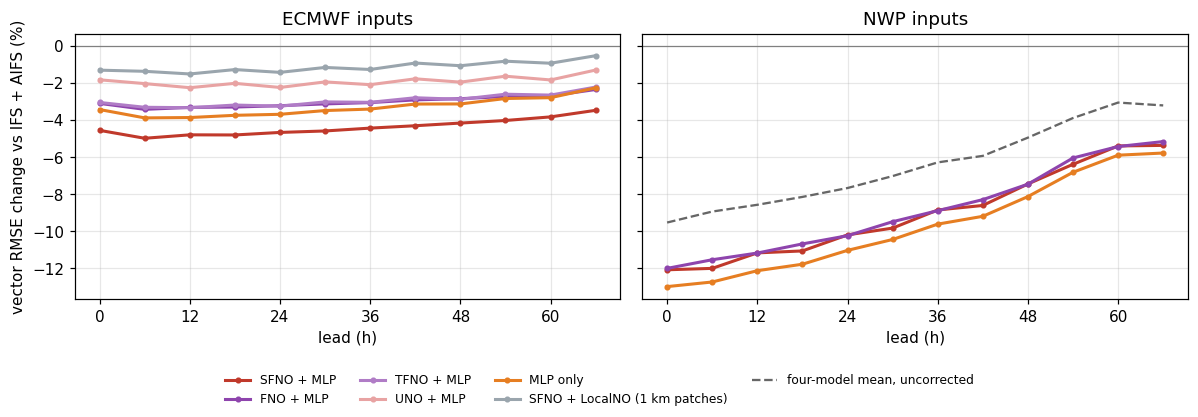

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
col = {'SFNO + MLP': '#c0392b', 'FNO + MLP': '#8e44ad', 'TFNO + MLP': '#b07cc6', 'UNO + MLP': '#e8a3a3',
       'MLP only': '#e67e22', 'SFNO + LocalNO (1 km patches)': '#9aa5ad'}
for a, g in zip(ax, ('ECMWF', 'NWP')):
    for (gg, lab), ch in res.items():
        if gg == g:
            a.plot(leads, ch.mean(0), '-o', ms=3, lw=2, color=col[lab], label=lab)
    if g == 'NWP':
        a.plot(leads, raw, '--', color='0.4', lw=1.5, label='four-model mean, uncorrected')
    a.axhline(0, color='0.5', lw=.8); a.set(title=f'{g} inputs', xlabel='lead (h)', xticks=leads[::2])
ax[0].set_ylabel('vector RMSE change vs IFS + AIFS (%)')
h = {l: x for a in ax for x, l in zip(*a.get_legend_handles_labels())}
fig.legend(h.values(), h.keys(), loc='lower center', ncol=4, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.12, 1, 1))

## Hourly values by interpolation

The models predict every 6 h. The website interpolates $u$ and $v$ linearly in time between two
model leads $t_k \le t \le t_{k+1}$:
$$\hat{\mathbf u}(t) = (1-w)\,\hat{\mathbf u}(t_k) + w\,\hat{\mathbf u}(t_{k+1}), \qquad w = \frac{t - t_k}{t_{k+1} - t_k}.$$
Below, the same is done for the reference (IFS + AIFS mean), and both are scored against the hourly
observations at the hours on and between the model leads.

In [3]:
H = np.arange(0, 67)
obs_h = np.stack([e['obs'][ti + h] for h in H], 1)[te]
def interp(p):
    k = np.clip(np.searchsorted(leads, H, side='right') - 1, 0, len(leads) - 2)
    w = ((H - leads[k]) / 6.0)[None, :, None, None]
    return p[:, k] * (1 - w) + p[:, k + 1] * w
def rm_h(p, on):
    m = np.isfinite(obs_h[..., 0]) & np.isfinite(p[..., 0]) & ((H % 6 == 0) == on)[None, :, None]
    return np.sqrt(((obs_h - p) ** 2).sum(-1)[m].mean())
ref = interp(base['ECMWF'])
rows = []
for g, m, sfx, lab in [c for c in CONFIGS if c[2] == '' and c[1] in ('sfno', 'fno', 'point')]:
    p = [interp(held_out(m, g, s)) for s in range(3)]
    rows.append({'inputs': g, 'model': lab,
                 'on the model leads (%)': np.mean([(rm_h(q, True) / rm_h(ref, True) - 1) * 100 for q in p]),
                 'between them (%)': np.mean([(rm_h(q, False) / rm_h(ref, False) - 1) * 100 for q in p])})
pd.DataFrame(rows).set_index(['inputs', 'model']).round(2)

on the model leads (%)  between them (%)
inputs model                                               
ECMWF  SFNO + MLP                   -4.36             -4.19
       FNO + MLP                    -2.99             -2.92
       MLP only                     -3.28             -3.31
NWP    SFNO + MLP                   -8.87             -8.72
       FNO + MLP                    -8.71             -8.60
       MLP only                     -9.53             -9.37

## Summary

* **Input forecasts matter most.** With the NWP group (adding GFS and the 2.5 km MEPS and
  AROME-Arctic), even the uncorrected four-model mean is about 6 % better than IFS + AIFS; the
  corrected models reach about −9 to −10 %, twice the best ECMWF model (−4.4 %).
* **The operator helps only with the ECMWF inputs, and only SFNO.** With IFS + AIFS, SFNO + MLP
  beats the MLP alone by about 1 percentage point; FNO, TFNO and UNO do not. SFNO has far fewer
  parameters (its spectral weights depend only on the degree $l$), which acts as a regulariser
  with 99 stations and 10 months of training data. With the NWP inputs the MLP alone is best: the
  2.5 km models already carry the local information.
* **The 1 km operator on terrain patches (LocalNO) memorises the stations** (−1.1 %).
* **Seeds:** differences below about 0.5 percentage points are within the seed spread.
* **Hourly:** interpolating the 6-hourly corrections keeps almost the whole improvement between the
  model leads, so the website shows hourly values.

**Website default:** MLP head with the NWP inputs.